<a href="https://colab.research.google.com/github/msanaullahchaudhary/kisaan-ai/blob/main/03_extra_field_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
!mkdir -p /content/drive/MyDrive/KisaanAI/data/extra
!wget --show-progress -O /content/pk.zip "https://data.mendeley.com/public-api/zip/3mbnb82mxd/download/1" 2>&1 | tail -n 5
!ls -lh /content/pk.zip

 94600K .......... .......... .......... .......... .......... 99%  229M 0s
 94650K .......... ..........                                 100%  404M=4.0s

2026-10-26 11:01:06 (22.8 MB/s) - ‘/content/pk.zip’ saved [96942245/96942245]

-rw-r--r-- 1 root root 93M Jan 30  2026 /content/pk.zip


In [10]:
import os
size_mb = os.path.getsize('/content/pk.zip') / 1e6
print(f'Downloaded: {size_mb:.0f} MB')
if size_mb > 1:
    !cp /content/pk.zip /content/drive/MyDrive/KisaanAI/data/extra/
    print('Saved to Drive')
else:
    print('Download failed - send me a screenshot')

Downloaded: 97 MB
Saved to Drive


In [11]:
import glob
!rm -rf /content/pk
!unzip -q -o /content/pk.zip -d /content/pk

for z in glob.glob('/content/pk/**/*.zip', recursive=True):
    print('Unzipping inner file:', z)
    !unzip -q -o "{z}" -d "{z[:-4]}"

!ls -la /content/pk
for root, dirs, files in os.walk('/content/pk'):
    imgs = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if imgs:
        print(len(imgs), root)

Unzipping inner file: /content/pk/Tomato Leaf Disease Classification Dataset in Paki/Tomato_Leaf_Dataset.zip
total 12
drwxr-xr-x 3 root root 4096 Oct 26 11:01  .
drwxr-xr-x 1 root root 4096 Oct 26 11:01  ..
drwxr-xr-x 3 root root 4096 Oct 26 11:01 'Tomato Leaf Disease Classification Dataset in Paki'
1200 /content/pk/Tomato Leaf Disease Classification Dataset in Paki/Tomato_Leaf_Dataset/Tomato_Leaf_Dataset/Tomato_Early_blight
1200 /content/pk/Tomato Leaf Disease Classification Dataset in Paki/Tomato_Leaf_Dataset/Tomato_Leaf_Dataset/Tomato_leaf_yellow_curl_virus
1200 /content/pk/Tomato Leaf Disease Classification Dataset in Paki/Tomato_Leaf_Dataset/Tomato_Leaf_Dataset/Tomato_mold_leaf
1200 /content/pk/Tomato Leaf Disease Classification Dataset in Paki/Tomato_Leaf_Dataset/Tomato_Leaf_Dataset/Tomato_leaf_late_blight
1200 /content/pk/Tomato Leaf Disease Classification Dataset in Paki/Tomato_Leaf_Dataset/Tomato_Leaf_Dataset/Tomato_septora_leaf_spot
1200 /content/pk/Tomato Leaf Disease Classi

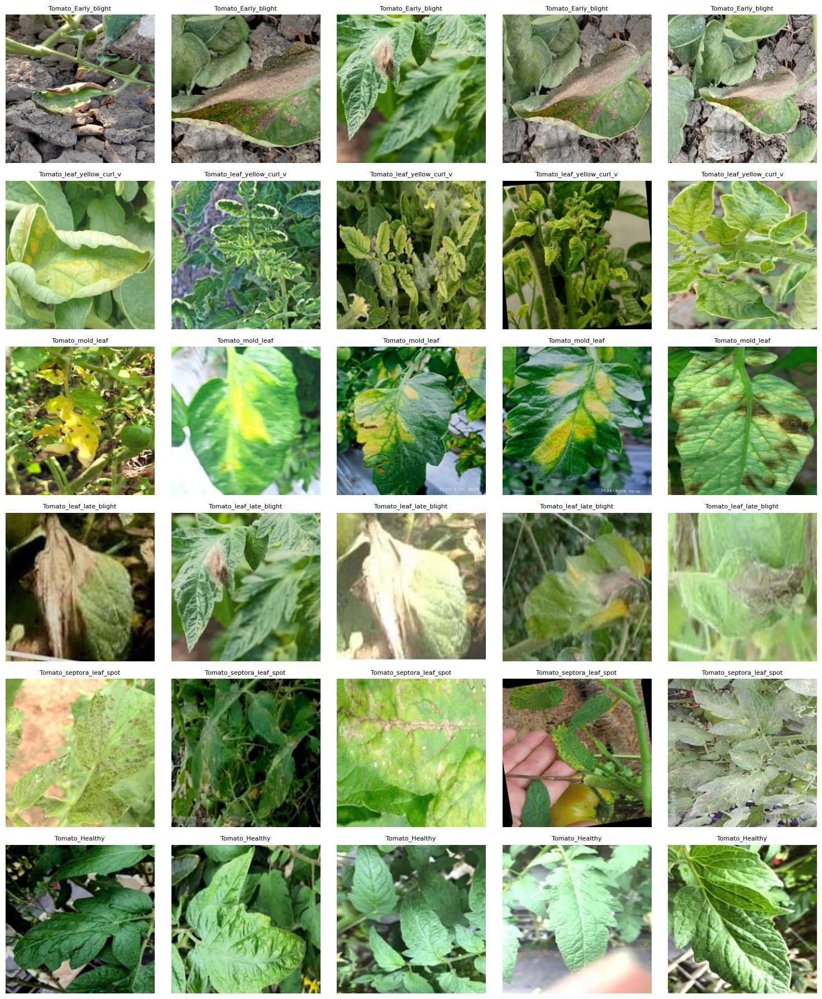

In [12]:
import random
import matplotlib.pyplot as plt
from PIL import Image

folders = []
for root, dirs, files in os.walk('/content/pk'):
    imgs = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if imgs:
        folders.append((root, imgs))

random.seed(0)
fig, ax = plt.subplots(len(folders), 5, figsize=(15, 3 * len(folders)), squeeze=False)
for r, (root, imgs) in enumerate(folders):
    for c, name in enumerate(random.sample(imgs, min(5, len(imgs)))):
        ax[r, c].imshow(Image.open(os.path.join(root, name)))
        ax[r, c].set_title(os.path.basename(root)[:25], fontsize=8)
for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

In [13]:
PK = os.path.dirname(glob.glob('/content/pk/**/Tomato_Early_blight', recursive=True)[0])
pk_names = {
    'Tomato_Early_blight': 'Early_blight',
    'Tomato_leaf_late_blight': 'Late_blight',
    'Tomato_septora_leaf_spot': 'Septoria_leaf_spot',
    'Tomato_mold_leaf': 'Leaf_mold',
    'Tomato_leaf_yellow_curl_virus': 'Yellow_Leaf_Curl_Virus',
    'Tomato_Healthy': 'Healthy',
}
pk_images = []
for folder, cls in pk_names.items():
    for name in sorted(os.listdir(os.path.join(PK, folder))):
        if name.lower().endswith(('.jpg', '.jpeg', '.png')):
            pk_images.append((os.path.join(PK, folder, name), cls))
print(len(pk_images), 'Pakistan photos')

7200 Pakistan photos


In [14]:
!cp /content/drive/MyDrive/KisaanAI/data/raw.zip /content/
!unzip -q -o /content/raw.zip 'raw/plantdoc/*' -d /content/

In [15]:
!pip install -q imagehash
import imagehash

def fingerprint(path):
    with Image.open(path) as im:
        return imagehash.phash(im.convert('RGB'))

pd_paths = [p for p in glob.glob('/content/raw/plantdoc/**/*', recursive=True)
            if p.lower().endswith(('.jpg', '.jpeg', '.png'))]
pd_hashes = [fingerprint(p) for p in pd_paths]
pk_hashes = [fingerprint(p) for p, cls in pk_images]
print(len(pd_hashes), 'PlantDoc fingerprints |', len(pk_hashes), 'Pakistan fingerprints')

744 PlantDoc fingerprints | 7200 Pakistan fingerprints


In [16]:
seen = set()
keep, leak, dup = [], 0, 0
for (path, cls), h in zip(pk_images, pk_hashes):
    if min(h - d for d in pd_hashes) <= 4:
        leak += 1
        continue
    if str(h) in seen:
        dup += 1
        continue
    seen.add(str(h))
    keep.append((path, cls))
print(f'Copies of PlantDoc photos: {leak} | exact repeats inside Pakistan set: {dup} | kept: {len(keep)}')

Copies of PlantDoc photos: 281 | exact repeats inside Pakistan set: 723 | kept: 6196


In [17]:
import pandas as pd

rows = []
for i, (path, cls) in enumerate(keep):
    folder = f'/content/pk_train/{cls}'
    os.makedirs(folder, exist_ok=True)
    new_name = f'pk_{i:05d}.jpg'
    with Image.open(path) as im:
        im = im.convert('RGB')
        im.thumbnail((512, 512))
        im.save(f'{folder}/{new_name}', quality=92)
    rows.append((new_name, cls, path.replace('/content/pk/', '')))

pk_df = pd.DataFrame(rows, columns=['new_name', 'class', 'source_path'])
pk_df.to_csv('/content/drive/MyDrive/KisaanAI/data/pk_train_files.csv', index=False)
print(pk_df['class'].value_counts())

!cd /content && zip -qr pk_train.zip pk_train
!cp /content/pk_train.zip /content/drive/MyDrive/KisaanAI/data/
!ls -lh /content/drive/MyDrive/KisaanAI/data/pk_train.zip

class
Healthy                   1109
Late_blight               1103
Leaf_mold                 1064
Septoria_leaf_spot        1037
Yellow_Leaf_Curl_Virus     948
Early_blight               935
Name: count, dtype: int64
-rw------- 1 root root 116M Oct 26 11:10 /content/drive/MyDrive/KisaanAI/data/pk_train.zip


Counter({'field_train': 220, 'field_val': 38, 'not in splits': 14, 'field_test': 9})


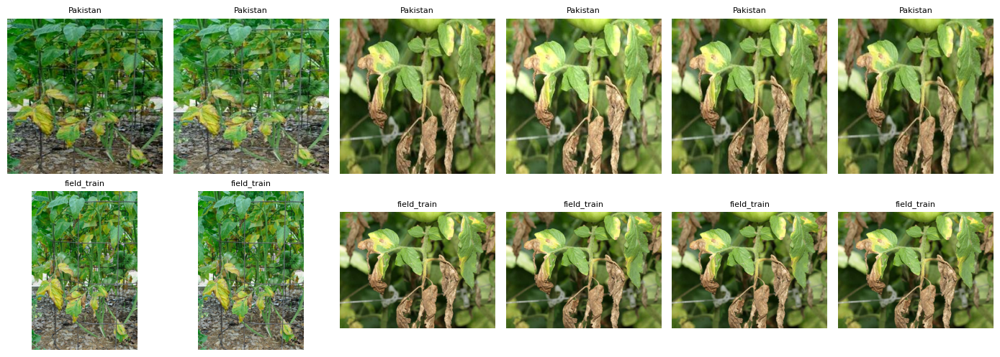

In [18]:
import numpy as np
from collections import Counter

splits = pd.read_csv('/content/drive/MyDrive/KisaanAI/data/splits.csv')
split_of = dict(zip('/content/raw/' + splits['path'], splits['split']))

pairs = []
for (path, cls), h in zip(pk_images, pk_hashes):
    dists = [h - d for d in pd_hashes]
    j = int(np.argmin(dists))
    if dists[j] <= 4:
        pairs.append((path, pd_paths[j]))

print(Counter(split_of.get(q, 'not in splits') for p, q in pairs))

fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for k, (p, q) in enumerate(pairs[:6]):
    ax[0, k].imshow(Image.open(p)); ax[0, k].set_title('Pakistan', fontsize=8)
    ax[1, k].imshow(Image.open(q)); ax[1, k].set_title(split_of.get(q, 'not in splits'), fontsize=8)
for a in ax.flat:
    a.axis('off')
plt.tight_layout(); plt.show()

In [19]:
import keras
encoder = keras.applications.MobileNetV3Large(input_shape=(224, 224, 3), include_top=False,
                                              weights='imagenet', include_preprocessing=True, pooling='avg')

def load_arr(p):
    with Image.open(p) as im:
        return np.asarray(im.convert('RGB').resize((224, 224)), dtype='float32')

def normalise(f):
    return f / np.linalg.norm(f, axis=1, keepdims=True)

# PlantDoc validation + test photos, each in 5 versions (normal, mirrored, rotated 90/180/270)
eval_paths = [p for p in pd_paths if split_of.get(p) in ('field_val', 'field_test')]
variants = []
for p in eval_paths:
    a = load_arr(p)
    variants += [a, np.fliplr(a), np.rot90(a, 1), np.rot90(a, 2), np.rot90(a, 3)]
eval_feats = normalise(encoder.predict(np.stack(variants), batch_size=64, verbose=0))

# all kept Pakistan photos, 500 at a time (to save memory)
pk_paths = [p for p, c in keep]
chunks = []
for i in range(0, len(pk_paths), 500):
    chunks.append(encoder.predict(np.stack([load_arr(p) for p in pk_paths[i:i + 500]]), batch_size=64, verbose=0))
pk_feats = normalise(np.concatenate(chunks))

sims = (pk_feats @ eval_feats.T).reshape(len(pk_paths), len(eval_paths), 5).max(axis=2)
best_sim, best_idx = sims.max(axis=1), sims.argmax(axis=1)
for t in [0.95, 0.90, 0.85, 0.80]:
    print(f'Pakistan photos with similarity >= {t}: {(best_sim >= t).sum()}')

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Pakistan photos with similarity >= 0.95: 57
Pakistan photos with similarity >= 0.9: 283
Pakistan photos with similarity >= 0.85: 1412
Pakistan photos with similarity >= 0.8: 3316


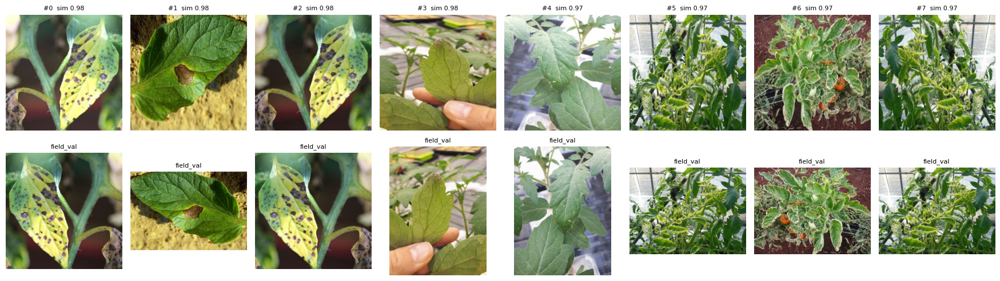

In [20]:
order = np.argsort(-best_sim)

def show_pairs(start, n=8):
    fig, ax = plt.subplots(2, n, figsize=(2.2 * n, 5), squeeze=False)
    for j, k in enumerate(order[start:start + n]):
        ax[0, j].imshow(Image.open(pk_paths[k])); ax[0, j].set_title(f'#{start + j}  sim {best_sim[k]:.2f}', fontsize=8)
        ax[1, j].imshow(Image.open(eval_paths[best_idx[k]])); ax[1, j].set_title(split_of[eval_paths[best_idx[k]]], fontsize=8)
    for a in ax.flat:
        a.axis('off')
    plt.tight_layout(); plt.show()

show_pairs(0)

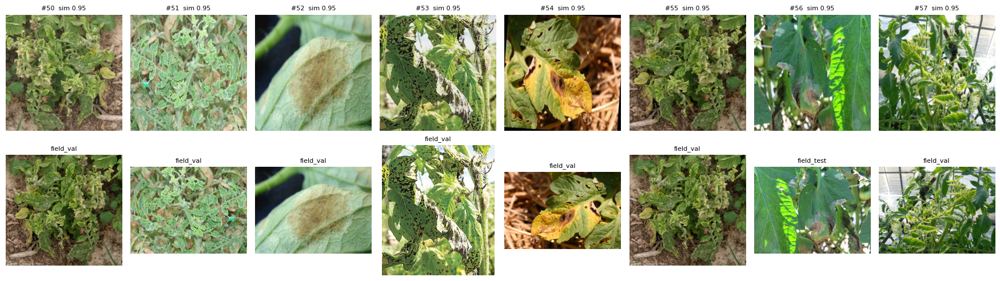

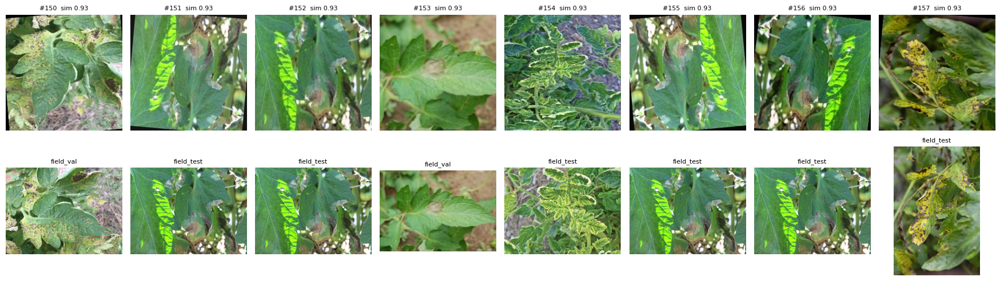

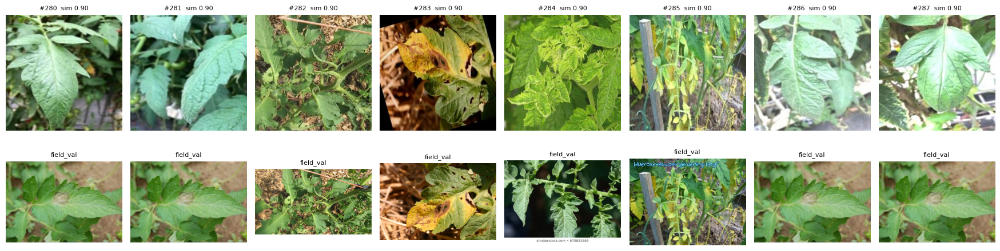

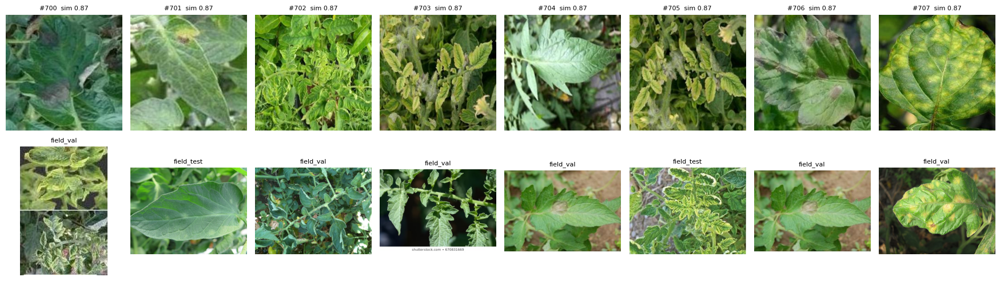

In [21]:
show_pairs(50)    # around similarity 0.95
show_pairs(150)   # around 0.92
show_pairs(280)   # around 0.90
show_pairs(700)   # around 0.87

Removed as possible copies of val/test photos: 1412 | clean Pakistan photos: 4784


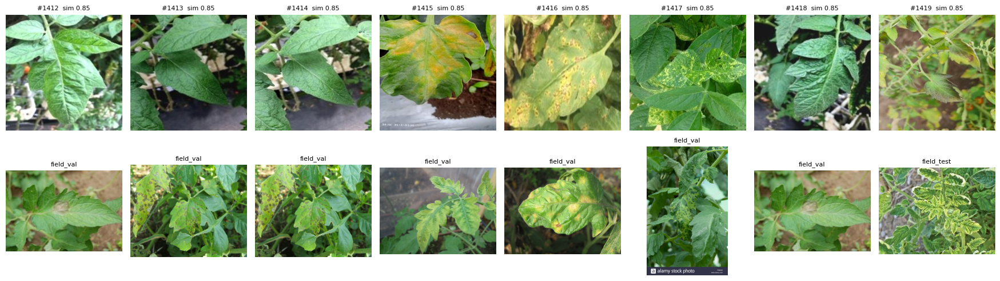

In [22]:
THRESH = 0.85
clean = [keep[i] for i in range(len(keep)) if best_sim[i] < THRESH]
print(f'Removed as possible copies of val/test photos: {len(keep) - len(clean)} | clean Pakistan photos: {len(clean)}')

removed = [(pk_paths[i].replace('/content/pk/', ''), round(float(best_sim[i]), 3),
            eval_paths[best_idx[i]].replace('/content/raw/', ''), split_of[eval_paths[best_idx[i]]])
           for i in range(len(keep)) if best_sim[i] >= THRESH]
pd.DataFrame(removed, columns=['pakistan_file', 'similarity', 'plantdoc_match', 'plantdoc_split']) \
  .to_csv('/content/drive/MyDrive/KisaanAI/data/pk_removed_copies.csv', index=False)

show_pairs(int((best_sim >= THRESH).sum()))   # the most similar photos we KEEP

In [23]:
!rm -rf /content/pk_train /content/pk_train.zip

rows = []
for i, (path, cls) in enumerate(clean):
    folder = f'/content/pk_train/{cls}'
    os.makedirs(folder, exist_ok=True)
    new_name = f'pk_{i:05d}.jpg'
    with Image.open(path) as im:
        im = im.convert('RGB')
        im.thumbnail((512, 512))
        im.save(f'{folder}/{new_name}', quality=92)
    rows.append((new_name, cls, path.replace('/content/pk/', '')))

pk_df = pd.DataFrame(rows, columns=['new_name', 'class', 'source_path'])
pk_df.to_csv('/content/drive/MyDrive/KisaanAI/data/pk_train_files.csv', index=False)
print(pk_df['class'].value_counts())

!cd /content && zip -qr pk_train.zip pk_train
!cp /content/pk_train.zip /content/drive/MyDrive/KisaanAI/data/
!ls -lh /content/drive/MyDrive/KisaanAI/data/pk_train.zip

class
Leaf_mold                 944
Late_blight               940
Septoria_leaf_spot        854
Early_blight              780
Yellow_Leaf_Curl_Virus    644
Healthy                   622
Name: count, dtype: int64
-rw------- 1 root root 89M Oct 26 11:32 /content/drive/MyDrive/KisaanAI/data/pk_train.zip
